# 코랩 설정

In [ ]:
!apt-get install -y mecab mecab-ipadic-utf8 libmecab-dev
!pip install konlpy
from google.colab import drive
drive.mount('/content/drive')

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libmecab2 mecab-ipadic mecab-utils
The following NEW packages will be installed:
  libmecab-dev libmecab2 mecab mecab-ipadic mecab-ipadic-utf8 mecab-utils
0 upgraded, 6 newly installed, 0 to remove and 41 not upgraded.
Need to get 7,367 kB of archives.
After this operation, 59.3 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 libmecab2 amd64 0.996-14build9 [199 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/main amd64 libmecab-dev amd64 0.996-14build9 [306 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/main amd64 mecab-utils amd64 0.996-14build9 [4,850 B]
Get:4 http://archive.ubuntu.com/ubuntu jammy/main amd64 mecab-ipadic all 2.7.0-20070801+main-3 [6,718 kB]
Get:5 http://archive.ubuntu.com/ubuntu jammy/universe amd64 mecab amd64 0.996-14build9 [136 kB]
Get:6 http://archive.ubuntu.co

# mps, cuda, cpu 설정

In [ ]:
import json
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
import re  # 정규표현식을 위해 추가
from torch.utils.data import DataLoader, TensorDataset, RandomSampler
from konlpy.tag import Okt
import nltk
from nltk.tokenize import word_tokenize
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json


nltk.download('punkt')
nltk.download('punkt_tab')
# 	Chaeyoon Kim신규
# mps는 맥이 아닌 환경에서는 에러가 날 수 있기 때문에, 다양한 환경에서는
if torch.backends.mps.is_available():
  device = torch.device("mps")
elif torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")
print(device)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


cuda


# 단어 토큰화

In [ ]:
train_json_file_path = "/content/drive/MyDrive/conversation/conversation_train_set.json"
valid_json_file_path = "/content/drive/MyDrive/conversation/conversation_valid_set.json"

SOS_token = 0
EOS_token = 1
PAD_token = 2
UNK_token = 3

okt = Okt()

# 전처리
def normalize_string(s):
    s = s.lower().strip()
    s = re.sub(r"([?.!,])", r" \1 ", s) # 문장부호 분리
    s = re.sub(r"[^a-zA-Z가-힣0-9?.!,]+", " ", s) # 특수문자 제거
    s = re.sub(r"\s+", " ", s).strip()
    return s
# 한국어 전처리
def preprocess_ko(text):
    text = normalize_string(text)
    tokens = okt.morphs(text)
    return tokens
# 영어 전처리
def preprocess_en(text):
    text = normalize_string(text)
    tokens = word_tokenize(text)
    return tokens

# json 읽어오기
def load_json(file_path, max_samples):
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    return data["data"][:max_samples]

data_train = load_json(train_json_file_path, max_samples=50000)

#  트레인 데이터셋 토큰화하고
# [
#     # 첫 번째 문장 쌍 (튜플)
#     (
#         ['안녕', '하', '세요', '!'],          # 한국어 토큰 리스트
#         ['Hello', '!']                       # 영어 토큰 리스트
#     ),

#     # 두 번째 문장 쌍
#     (
#         ['오늘', '날씨', '참', '좋', '네요'],
#         ['The', 'weather', 'is', 'good', 'today']
#     ),

#     # ... (5만 개)
# ]


train_pairs_tokens = []
for item in data_train:
    ko_toks = preprocess_ko(item["ko"])
    en_toks = preprocess_en(item["en"])
    if len(ko_toks) > 0 and len(en_toks) > 0: # 토큰화된게 1이상만
        train_pairs_tokens.append((ko_toks, en_toks))



data_valid = load_json(valid_json_file_path, max_samples=1000)

valid_pairs_tokens = []
for item in data_valid:
    ko_toks = preprocess_ko(item["ko"])
    en_toks = preprocess_en(item["en"])
    if len(ko_toks) > 0 and len(en_toks) > 0:
        valid_pairs_tokens.append((ko_toks, en_toks))



ko_lengths = [len(p[0]) for p in train_pairs_tokens]
en_lengths = [len(p[1]) for p in train_pairs_tokens]
all_lengths = ko_lengths + en_lengths

# MAX_LENGTH = max(all_lengths) + 2
# print(f"Max sequence length: {MAX_LENGTH}")

MAX_LENGTH = 32
print(f"Max sequence length: {MAX_LENGTH}")


# class Lang:
#     def __init__(self, name):
#         self.name = name
#         self.word2index = {"PAD": PAD_token, "SOS": SOS_token, "EOS": EOS_token, "<unk>": UNK_token}
#         self.index2word = {PAD_token: "PAD", SOS_token: "SOS", EOS_token: "EOS", UNK_token: "<unk>"}
#         self.word2count = {}
#         self.n_words = 4

#     def addSentence(self, tokens):
#         for word in tokens:
#             self.addWord(word)

#     def addWord(self, word):
#         if word not in self.word2index:
#             self.word2index[word] = self.n_words
#             self.index2word[self.n_words] = word
#             self.word2count[word] = 1
#             self.n_words += 1
#         else:
#             self.word2count[word] += 1

# # 단어장 생성하기
# def prepareData(lang1, lang2, pairs_tokens):
#     input_lang = Lang(lang1)
#     output_lang = Lang(lang2)

#     for ko_toks, en_toks in pairs_tokens:
#         input_lang.addSentence(ko_toks)
#         output_lang.addSentence(en_toks)

#     return input_lang, output_lang

# input_lang, output_lang = prepareData("ko", "en", train_pairs_tokens)

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {"PAD": PAD_token, "SOS": SOS_token, "EOS": EOS_token, "<unk>": UNK_token}
        self.index2word = {PAD_token: "PAD", SOS_token: "SOS", EOS_token: "EOS", UNK_token: "<unk>"}
        self.word2count = {}
        self.n_words = 4

    def addSentence(self, tokens):
        for word in tokens:
            self.addWord(word)

    def addWord(self, word):
        # 일단 카운트만 무조건 올림
        if word not in self.word2count:
            self.word2count[word] = 1
        else:
            self.word2count[word] += 1

    # [추가됨] 모든 데이터를 다 훑은 뒤에 호출하는 함수
    def build_vocab(self, min_freq=3):
        # 기존 등록된 단어들 초기화 (특수 토큰만 남김)
        self.word2index = {"PAD": PAD_token, "SOS": SOS_token, "EOS": EOS_token, "<unk>": UNK_token}
        self.index2word = {PAD_token: "PAD", SOS_token: "SOS", EOS_token: "EOS", UNK_token: "<unk>"}
        self.n_words = 4

        # 빈도수 체크해서 등록
        filtered_count = 0
        for word, count in self.word2count.items():
            if count >= min_freq:
                self.word2index[word] = self.n_words
                self.index2word[self.n_words] = word
                self.n_words += 1
            else:
                filtered_count += 1

        print(f"[{self.name}] Total words: {len(self.word2count)} -> Kept: {self.n_words-4} (Filtered: {filtered_count})")

# --- 사용법 수정 ---
def prepareData(lang1, lang2, pairs_tokens, min_freq=3):
    input_lang = Lang(lang1)
    output_lang = Lang(lang2)

    print("Counting words...")
    for ko_toks, en_toks in pairs_tokens:
        input_lang.addSentence(ko_toks)
        output_lang.addSentence(en_toks)

    # [중요] 다 세고 나서 여기서 필터링 수행!
    print(f"Building vocab with min_freq={min_freq}...")
    input_lang.build_vocab(min_freq)
    output_lang.build_vocab(min_freq)

    return input_lang, output_lang

# 실행
input_lang, output_lang = prepareData("ko", "en", train_pairs_tokens, min_freq=3)

# 텐셔 변환
def tensorFromSentence(lang, tokens):
    if len(tokens) > MAX_LENGTH - 2:
        tokens = tokens[:MAX_LENGTH - 2]

    indexes = [SOS_token]
    indexes += [lang.word2index.get(word, UNK_token) for word in tokens]
    indexes.append(EOS_token)

    while len(indexes) < MAX_LENGTH:
        indexes.append(PAD_token)

    return torch.tensor(indexes, dtype=torch.long, device=device)

# 데이터 로더생성
def get_dataloader(batch_size, pairs_tokens, shuffle=True):
    print(f"Converting {len(pairs_tokens)} pairs to tensors...")
    input_tensors = [tensorFromSentence(input_lang, p[0]) for p in pairs_tokens]
    target_tensors = [tensorFromSentence(output_lang, p[1]) for p in pairs_tokens]

    input_tensors = torch.stack(input_tensors, dim=0)
    target_tensors = torch.stack(target_tensors, dim=0)

    dataset = TensorDataset(input_tensors, target_tensors)

    if shuffle:
        sampler = RandomSampler(dataset) # Train용
    else:
        sampler = None # Valid용 (순서대로 평가)

    dataloader = DataLoader(dataset, sampler=sampler, batch_size=batch_size, shuffle=(sampler is None))

    print(f"Created dataloader with shape: {input_tensors.shape}")
    return dataloader
train_dataloader = get_dataloader(batch_size=32, pairs_tokens=train_pairs_tokens, shuffle=True)
valid_dataloader = get_dataloader(batch_size=32, pairs_tokens=valid_pairs_tokens, shuffle=False)

Max sequence length: 32
Counting words...
Building vocab with min_freq=3...
[ko] Total words: 31977 -> Kept: 11556 (Filtered: 20421)
[en] Total words: 17032 -> Kept: 8027 (Filtered: 9005)
Converting 50000 pairs to tensors...
Created dataloader with shape: torch.Size([50000, 32])
Converting 1000 pairs to tensors...
Created dataloader with shape: torch.Size([1000, 32])


- korean stopwords 리스트들 여러개 봤는데 다 중요한 단어라고 생각됨...
- 불용어 제거 안 함.

# 토큰 개수 시각화


=== 한국어 문장 길이 통계 ===
count    50000.000000
mean        11.061860
std          6.391742
min          1.000000
25%          6.000000
50%         10.000000
75%         15.000000
max         96.000000
Name: ko_token_len, dtype: float64

=== 영어 문장 길이 통계 ===
count    50000.000000
mean        11.587840
std          6.325169
min          1.000000
25%          7.000000
50%         11.000000
75%         15.000000
max         78.000000
Name: en_token_len, dtype: float64


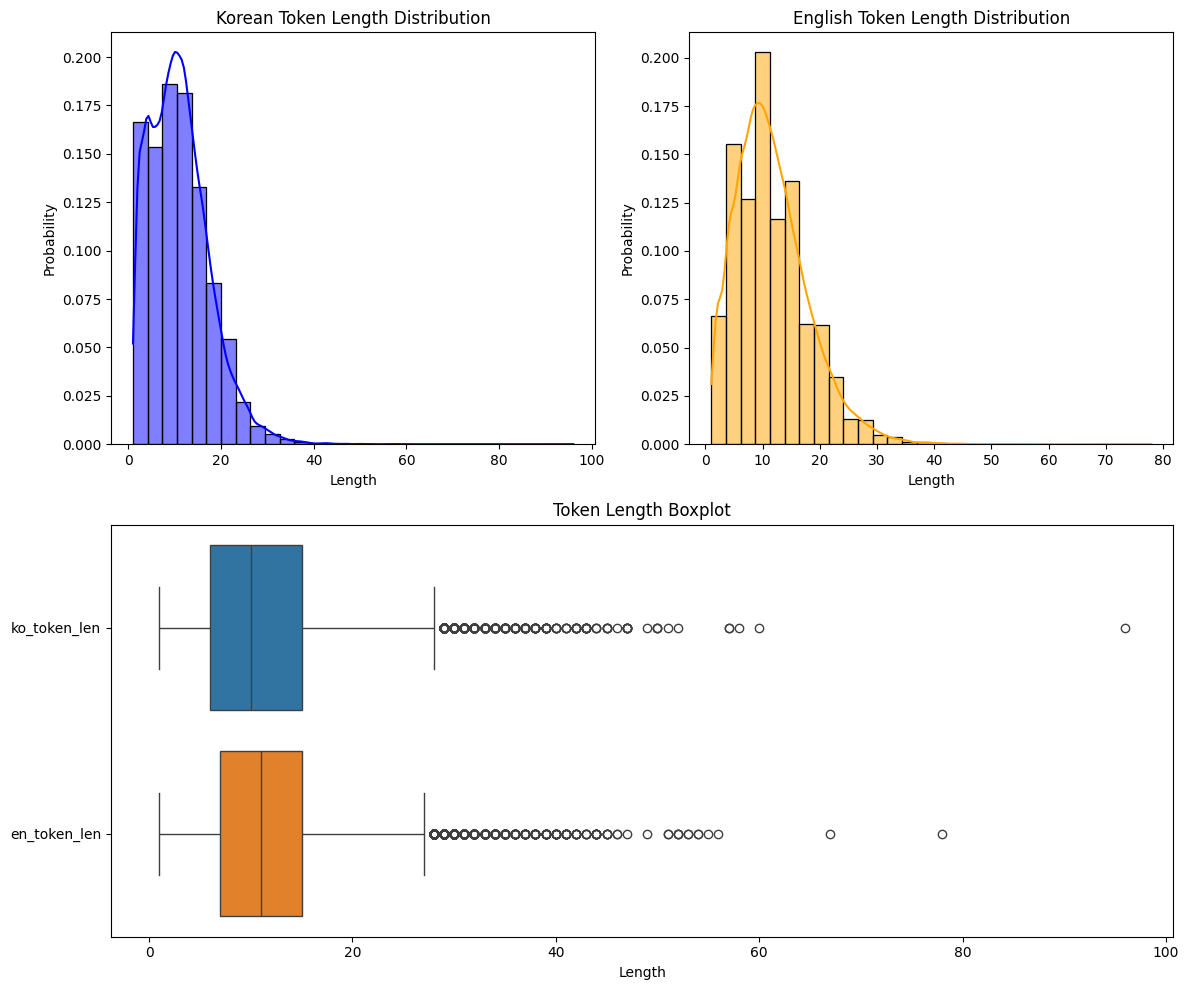


[검증] 데이터의 99%를 포함하는 MAX_LENGTH: 32


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.DataFrame(train_pairs_tokens, columns=['ko_tokens', 'en_tokens'])


df['ko_token_len'] = df['ko_tokens'].apply(len)
df['en_token_len'] = df['en_tokens'].apply(len)


print("\n=== 한국어 문장 길이 통계 ===")
print(df['ko_token_len'].describe())

print("\n=== 영어 문장 길이 통계 ===")
print(df['en_token_len'].describe())


plt.figure(figsize=(12, 10))

# 한국어 길이 분포
plt.subplot(2, 2, 1)
sns.histplot(
    df['ko_token_len'],
    bins=30,
    kde=True,
    color='blue',
    stat="probability"
)
plt.title('Korean Token Length Distribution')
plt.xlabel('Length')
plt.ylabel('Probability')

# 영어 길이 분포
plt.subplot(2, 2, 2)
sns.histplot(
    df['en_token_len'],
    bins=30,
    kde=True,
    color='orange',
    stat="probability"
)
plt.title('English Token Length Distribution')
plt.xlabel('Length')
plt.ylabel('Probability')

# 박스플롯
plt.subplot(2, 1, 2)
sns.boxplot(data=df[['ko_token_len', 'en_token_len']], orient='h')
plt.title('Token Length Boxplot')
plt.xlabel('Length')

plt.tight_layout()
plt.show()

ko_max = df['ko_token_len'].quantile(0.99)
en_max = df['en_token_len'].quantile(0.99)
final_max = max(ko_max, en_max) + 2

print(f"\n[검증] 데이터의 99%를 포함하는 MAX_LENGTH: {int(final_max)}")

# 시각화 결과
## 한국어
- 평균, 중앙 10~11로 비슷 -> 이상치 괜찮고, 분포 괜찮음
- 최소 0 -> 이건 뽑아서 삭제하기 -> 토큰화때 했음
- 최대 95토큰에 (특수토큰포함하면 97) 99%의 데이터가 32토큰 아래.
- IQR outlier가 28.5니깐 29 단어에 앞뒤 토큰 추가하면 32 정도를 Max Length로 지정 할 예정

## 영어
- 평균, 중앙 11로 비슷
- 최소 0 > 똑같이 삭제하기 -> 토큰화 때 함
- 최대 78 토큰에
- IQR outlier가 27이니깐 앞뒤 특수토큰에 29에 한국어 32니깐 MaxLength 32


# 단어장 내부 모습
## 최소 1번 등장
- 한: 약 32000
- 영: 약 17000

## 최소 2번 등장
- 한: 16080
- 영: 10453
2번만 진행해도 절반 가량 줄어듦
-----------------------
## 최소 3번 등장
- 한: 약 11555
- 영: 8028


In [ ]:
print(f"한국어 단어장 크기: {input_lang.n_words}개")
print(f"영어 단어장 크기: {output_lang.n_words}개")

한국어 단어장 크기: 11555개
영어 단어장 크기: 8028개


## UNK 비율 확인
- min_freq 3번으로해도 UNk 비율이 5퍼 미만임. min_freq = 3으로 함

In [ ]:
def check_unk_ratio(lang, min_freq=3):
    total_tokens = sum(lang.word2count.values()) # 전체 토큰 등장 횟수 합
    unk_tokens = 0

    for word, count in lang.word2count.items():
        if count < min_freq:
            unk_tokens += count # 탈락한 단어들의 등장 횟수 누적

    ratio = (unk_tokens / total_tokens) * 100
    print(f"[{lang.name}] Total Tokens: {total_tokens}, UNK Tokens: {unk_tokens}")
    print(f"UNK Ratio: {ratio:.2f}%")

# 실행 (min_freq=3 기준)
check_unk_ratio(input_lang, min_freq=3)
check_unk_ratio(output_lang, min_freq=3)

check_unk_ratio(input_lang, min_freq=2)
check_unk_ratio(output_lang, min_freq=2)

[ko] Total Tokens: 551346, UNK Tokens: 24946
UNK Ratio: 4.52%
[en] Total Tokens: 579058, UNK Tokens: 11429
UNK Ratio: 1.97%
[ko] Total Tokens: 551346, UNK Tokens: 15896
UNK Ratio: 2.88%
[en] Total Tokens: 579058, UNK Tokens: 6579
UNK Ratio: 1.14%


# Seq2Seq

In [ ]:
import torch.nn.functional as F

# Encoder 정의
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.1):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        embedded = self.dropout(self.embedding(input))
        output, hidden = self.gru(embedded)
        return output, hidden # 히든이 다음셀로, 아웃풋이 각 단어별로(어텐션 아니니깐 안 씀)

# Decoder 정의
class DecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p = 0.0):
        super(DecoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.dropout = nn.Dropout(dropout_p)  # 드롭 아웃 선언 추가함
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None): # 문장 전체
        batch_size = encoder_outputs.size(0)
        # 초기 디코더 입력: SOS 토큰 ([batch_size, 1])
        # sos로 시작
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=encoder_outputs.device).fill_(SOS_token)
        # 인코더 히든을 받아옴 contextvecor인듯
        decoder_hidden = encoder_hidden

        decoder_outputs = []

        for i in range(MAX_LENGTH):
            # 인풋(티쳐 포싱)이랑 전 셀의 히든 받아서
            decoder_output, decoder_hidden = self.forward_step(decoder_input, decoder_hidden)
            decoder_outputs.append(decoder_output)

            if target_tensor is not None: # 학습할때
                # Teacher forcing: target_tensor의 i번째 토큰 사용 ([batch_size, 1])
                decoder_input = target_tensor[:, i].unsqueeze(1)
            else:
                # ㅈ정답이 없으니 예측한 1등을 다음 입력으로
                _, topi = decoder_output.topk(1)
                # topi의 shape: [batch_size, 1, 1] → squeeze 마지막 차원만 제거하여 [batch_size, 1]
                decoder_input = topi.squeeze(2).detach()# 역전파 계산 X

        # [batch_size, MAX_LENGTH, output_size]
        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1) # 소프트맥스에 로그
        return decoder_outputs, decoder_hidden, None # 여기선 아웃풋을 써야됨

    def forward_step(self, input, hidden): # 단어 하나
        # input: [batch_size, 1]
        output = self.embedding(input)          # → [batch_size, 1, hidden_size]
        # output = F.relu(output)
        output = self.dropout(output) # 드롭아웃 추가
        output, hidden = self.gru(output, hidden) # output: [batch_size, 1, hidden_size]
        output = self.out(output)                 # → [batch_size, 1, output_size]
        return output, hidden


# 고친 것
- forward_step에서 임베딩 -> Relu -> cell 순서인데, EMbedding 후에 relu를 쓰면 임베딩 ex) [0.1, -0.2, 0.3]가 됨. 0이하면 0으로 하는 Relu 특성상 손실되는 값이 너무 많이 생길 거 같아서 뺌. 베이스 라인에서 오버피팅을 막으려고그런건지 활성화함수를 쓰려고 한건진 잘 모르겠지만...
- 오버피팅을 막기 위한 거라면 드롭아웃이 좀 더 점근적인 방식인듯... gru 셀 안에서도 이미 하이퍼볼릭탄젠트 적용을 하기도 하고...
- 드롭아웃 그냥 0으로 함. 30에폭 기준으로도 그렇게 똑똑하지 않은듯함

In [ ]:

def train_epoch(dataloader, encoder, decoder, encoder_optimizer,
                decoder_optimizer, criterion):
    encoder.train()
    decoder.train()

    total_loss = 0
    for data in dataloader:
        input_tensor, target_tensor = data

        # 반드시 정수(LongTensor)로 변환
        input_tensor = input_tensor.long().to(device)
        target_tensor = target_tensor.long().to(device)

        encoder_optimizer.zero_grad()
        decoder_optimizer.zero_grad()

        encoder_outputs, encoder_hidden = encoder(input_tensor)
        decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor)

        loss = criterion(
            decoder_outputs.view(-1, decoder_outputs.size(-1)),
            target_tensor.view(-1)
        )
        loss.backward()

        encoder_optimizer.step()
        decoder_optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)
# 학습 시작
def train_seq2seq(train_dataloader, encoder, decoder, n_epochs, learning_rate=0.001):
    print_loss_total = 0

    encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)

    criterion = nn.NLLLoss(ignore_index=PAD_token) # 패딩 계산안하기

    for epoch in range(1, n_epochs + 1):
        loss = train_epoch(train_dataloader, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion)


        wandb.log({"epoch": epoch, "train_loss": loss})

    wandb.finish()

In [ ]:
import wandb

# Start a new wandb run to track this script.
wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="yoonwogud-lab",
    # Set the wandb project where this run will be logged.
    project="Seq2Seq-Attention",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.001,
        "architecture": "Seq2Seq",
        "optim": "Adam",
        "criterion":"NLLLoss",
        "epochs": 30,
        "hidden-size": 256,
        "MaxLength": 32,

    },
)

hidden_size = 256
encoder = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder = DecoderRNN(hidden_size, output_lang.n_words).to(device)

train_seq2seq(train_dataloader, encoder, decoder, n_epochs=30)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: yoonwogud (yoonwogud-lab) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
train_loss,█▆▅▅▄▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
epoch,30
train_loss,0.98013


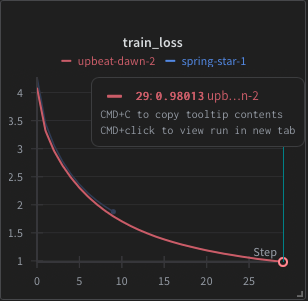

- 로스 잘 줄어드는데 에폭 늘리면 더 줄어들 수 있을 것 같음.

In [ ]:
def evaluate(encoder, decoder, sentence, input_lang, output_lang):
    encoder.eval()
    decoder.eval()

    with torch.no_grad():
        # 1. [수정] 문자열을 먼저 토큰화합니다.
        tokens = preprocess_ko(sentence)

        # 2. [수정] 토큰 리스트만 넘깁니다. (preprocess_ko 인자 제거)
        input_tensor = tensorFromSentence(input_lang, tokens).unsqueeze(0)

        encoder_outputs, encoder_hidden = encoder(input_tensor)
        # decoder 호출 시 target_tensor는 없으므로 생략 (Teacher Forcing X)
        decoder_outputs, decoder_hidden, _ = decoder(encoder_outputs, encoder_hidden)

        _, topi = decoder_outputs.topk(1)
        decoded_ids = topi.squeeze()

        decoded_words = []
        for idx in decoded_ids:
            idx_item = idx.item()
            if idx_item == EOS_token:
                decoded_words.append('<EOS>')
                break
            # 단어장에 없는 단어 처리
            word = output_lang.index2word.get(idx_item, "<unk>")
            decoded_words.append(word)

    return decoded_words, None
def evaluateRandomly(encoder, decoder, n=10):
    for i in range(n):
        pair = random.choice(pairs)
        print('>', pair[0])
        print('=', pair[1])

        output_words, _ = evaluate(encoder, decoder, pair[0], input_lang, output_lang)

        # <SOS>, <EOS>, SOS, EOS 등을 제거
        tokens_to_remove = ['<SOS>', 'SOS', '<EOS>', 'EOS']
        output_words = [w for w in output_words if w not in tokens_to_remove]

        output_sentence = ' '.join(output_words)
        print('<', output_sentence)
        print('')

In [ ]:
pairs= [(item['ko'], item['en']) for item in data_valid]

print("Read %s validation sentence pairs" % len(pairs))

Read 1000 validation sentence pairs


In [ ]:
evaluateRandomly(encoder, decoder)

> 우리는 발생한 총비용의 절반을 부담할 것이다.
= We will bear half of the total cost incurred.
< we will also sell a cost to sell our equipment .

> 핫팩을 손에 쥐고 있다 다시 주머니에 넣었다를 반복하시면 좀 더 따뜻함을 오래 느끼실 것입니다.
= Repeat holding a hot pack in your hand and putting it in your pocket again, and you will feel warmer for a longer time.
< if you look at the washing machine and rest , you will get more water more added more than twice a week .

> >다 일어나.
= Everyone, get up.
< wake up .

> >오빠, 시민이었던 거야?
= > Oppa, were you a citizen?
< oppa , is it a real fan ?

> 드론은 우리에게 많은 도움이 되었습니다.
= The drone helped us out a lot.
< our business center is also nice .

> 내일 모레 각기 다른 부서에서 근무 중인 30명의 직원들이 해고될 것입니다.
= The day after tomorrow, 30 employees in different departments will be laid off.
< it will be the second banquet hall and the restaurant ran positively in the middle .

> 저희 제품은 미끄럼 패드가 장착되어 있어서 미끄럽지 않으며, 탑승감도 훨씬 좋을 겁니다.
= Our product is equipped with a slide pad, so it's not slippery, and the boarding feeling will be much

- 데이터셋 분포 보면 비지니스가 많던데 그거에 해당하는 뉘앙스, 단어가 좀 추가된 듯함.
- oppa 같은 특수한 단어는 잘 맞히는 듯함.
- UNK 비율이 그렇게 높지않은 걸 봐서 okt -> sentence piece로 해도 드라마틱한 변화는 없어보임
- 문맥이 쓰레기 같은데 hidden 사이즈를 늘리면 괜찮아질 거 같음.
- 그렇다고 짧은 것을 잘 맞추는 건 아님. 너무 섞여버려서 알맞는 단어 찾기가 힘든듯 -> 어텐션으로 인코더 정보 보는게 맞는듯.


In [ ]:
from nltk.translate.bleu_score import corpus_bleu

def calculate_bleu(encoder, decoder, data_source):
    references = [] # 정답지 모음 [[['I', 'am', 'boy'], ...], ...]
    hypotheses = [] # 모델 예측 모음 [['I', 'm', 'boy'], ...]

    print("Calculating BLEU score...")

    # data_source는 data_valid (딕셔너리 리스트)
    for i, item in enumerate(data_source):
        src_sentence = item["ko"]
        tgt_sentence = item["en"]

        # 1. 모델 예측 (Hypothesis)
        output_words, _ = evaluate(encoder, decoder, src_sentence, input_lang, output_lang)

        # 특수 토큰 제거
        pred_tokens = [w for w in output_words if w not in ['SOS', '<EOS>', 'PAD']]
        hypotheses.append(pred_tokens)

        # 2. 정답 (Reference) - 전처리된 토큰 리스트 필요
        # (주의: BLEU는 정답이 여러 개일 수 있어서 리스트의 리스트로 감싸야 함)
        ref_tokens = preprocess_en(tgt_sentence)
        references.append([ref_tokens])

        if i % 100 == 0:
            print(f"{i}/{len(data_source)} processed")

    # 3. BLEU 계산
    # weights=(1, 0, 0, 0) -> BLEU-1 (단어 1개씩 맞는지)
    # weights=(0.25, 0.25, 0.25, 0.25) -> BLEU-4 (일반적인 기준)
    bleu_score = corpus_bleu(references, hypotheses)
    print(f"\nBLEU Score: {bleu_score * 100:.2f}")

    return bleu_score

# 실행
calculate_bleu(encoder, decoder, data_valid)

Calculating BLEU score...
0/1000 processed
100/1000 processed
200/1000 processed
300/1000 processed
400/1000 processed
500/1000 processed
600/1000 processed
700/1000 processed
800/1000 processed
900/1000 processed

BLEU Score: 7.34


0.07336966809104767

- 쓰레기 모델임

# Seq2Seq with Attention

In [ ]:
import torch.nn.functional as F

class BahdanauAttention(nn.Module):
    def __init__(self, hidden_size):
        super(BahdanauAttention, self).__init__()
        self.Wa = nn.Linear(hidden_size, hidden_size) # 가중치 연산
        self.Ua = nn.Linear(hidden_size, hidden_size)
        self.Va = nn.Linear(hidden_size, 1)

    def forward(self, query, keys):
        scores = self.Va(torch.tanh(self.Wa(query) + self.Ua(keys))) # 스코어 계산
        scores = scores.squeeze(2).unsqueeze(1)

        weights = F.softmax(scores, dim=-1)
        # 트랜스포머. 스코어에 소프트맥스, 어텐셩 웨이트, 어텐션 밸류 순
        context = torch.bmm(weights, keys)# Batch Matrix Multiplication, 배치끼리 묶어서 한번에 행렬곱

        return context, weights

class AttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.0):
        super(AttnDecoderRNN, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.attention = BahdanauAttention(hidden_size)
        self.gru = nn.GRU(2 * hidden_size, hidden_size, batch_first=True)# 디코더 인풋 + 인코더 압축하넉
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0) # 배치
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token) # 첫단ㅇ어 sos
        decoder_hidden = encoder_hidden # 인코더 마지막 벡터
        decoder_outputs = []
        attentions = []

        for i in range(MAX_LENGTH): # 32번
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs
            )
            decoder_outputs.append(decoder_output) #단어 예측 결과 저장
            attentions.append(attn_weights) # 어텐션 가중치, 단어 만들때 몇번째 단어를 얼만큼 봣다.

            if target_tensor is not None:
                # Teacher forcing: Feed the target as the next input
                decoder_input = target_tensor[:, i].unsqueeze(1) # Teacher forcing
            else:
                # Without teacher forcing: use its own predictions as the next input
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()  # detach from history as input

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        attentions = torch.cat(attentions, dim=1)

        return decoder_outputs, decoder_hidden, attentions


    def forward_step(self, input, hidden, encoder_outputs):
        embedded =  self.dropout(self.embedding(input))

        query = hidden.permute(1, 0, 2)
        context, attn_weights = self.attention(query, encoder_outputs)
        input_gru = torch.cat((embedded, context), dim=2)

        output, hidden = self.gru(input_gru, hidden)
        output = self.out(output)

        return output, hidden, attn_weights

In [ ]:

def train_epoch(dataloader, encoder, decoder, encoder_optimizer,
                decoder_optimizer, criterion):
    encoder.train()
    decoder.train()

    total_loss = 0
    for data in dataloader:
        input_tensor, target_tensor = data

        # 반드시 정수(LongTensor)로 변환
        input_tensor = input_tensor.long().to(device)
        target_tensor = target_tensor.long().to(device)

        encoder_optimizer.zero_grad()
        decoder_optimizer.zero_grad()

        encoder_outputs, encoder_hidden = encoder(input_tensor)
        decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor)

        loss = criterion(
            decoder_outputs.view(-1, decoder_outputs.size(-1)),
            target_tensor.view(-1)
        )
        loss.backward()

        encoder_optimizer.step()
        decoder_optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)
# 학습 시작
def train_seq2seq(train_dataloader, encoder, decoder, n_epochs, learning_rate=0.001):
    print_loss_total = 0

    encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)

    criterion = nn.NLLLoss(ignore_index=PAD_token) # 패딩 계산안하기

    for epoch in range(1, n_epochs + 1):
        loss = train_epoch(train_dataloader, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion)


        wandb.log({"epoch": epoch, "train_loss": loss})

    wandb.finish()

In [ ]:
# 모델 초기화 및 학습 실행
import wandb
hidden_size = 256
encoder = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder = AttnDecoderRNN(hidden_size, output_lang.n_words).to(device)

# 모델 학습 실행

# Start a new wandb run to track this script.
wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="yoonwogud-lab",
    # Set the wandb project where this run will be logged.
    project="Seq2Seq-Attention",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.001,
        "architecture": "Attention",
        "optim": "Adam",
        "criterion":"NLLLoss",
        "epochs": 30,
        "hidden-size": 256,
        "MaxLength": 32,

    },
)
train_seq2seq(train_dataloader, encoder, decoder, n_epochs=30)

epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
train_loss,█▆▅▄▄▄▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
epoch,30
train_loss,0.8468


In [ ]:
from nltk.translate.bleu_score import corpus_bleu

def calculate_bleu(encoder, decoder, data_source):
    references = [] # 정답지 모음 [[['I', 'am', 'boy'], ...], ...]
    hypotheses = [] # 모델 예측 모음 [['I', 'm', 'boy'], ...]

    print("Calculating BLEU score...")

    # data_source는 data_valid (딕셔너리 리스트)
    for i, item in enumerate(data_source):
        src_sentence = item["ko"]
        tgt_sentence = item["en"]

        # 1. 모델 예측 (Hypothesis)
        output_words, _ = evaluate(encoder, decoder, src_sentence, input_lang, output_lang)

        # 특수 토큰 제거
        pred_tokens = [w for w in output_words if w not in ['SOS', '<EOS>', 'PAD']]
        hypotheses.append(pred_tokens)

        # 2. 정답 (Reference) - 전처리된 토큰 리스트 필요
        # (주의: BLEU는 정답이 여러 개일 수 있어서 리스트의 리스트로 감싸야 함)
        ref_tokens = preprocess_en(tgt_sentence)
        references.append([ref_tokens])

        if i % 100 == 0:
            print(f"{i}/{len(data_source)} processed")

    # 3. BLEU 계산
    # weights=(1, 0, 0, 0) -> BLEU-1 (단어 1개씩 맞는지)
    # weights=(0.25, 0.25, 0.25, 0.25) -> BLEU-4 (일반적인 기준)
    bleu_score = corpus_bleu(references, hypotheses)
    print(f"\nBLEU Score: {bleu_score * 100:.2f}")

    return bleu_score

# 실행
calculate_bleu(encoder, decoder, data_valid)

Calculating BLEU score...
0/1000 processed
100/1000 processed
200/1000 processed
300/1000 processed
400/1000 processed
500/1000 processed
600/1000 processed
700/1000 processed
800/1000 processed
900/1000 processed

BLEU Score: 11.87


0.11868888167448705

1. BLEU (Bilingual Evaluation Understudy)
"정밀도(Precision) 중심: 틀린 말을 안 하는 게 중요하다!"

주로 쓰는 곳: 기계 번역
채점 방식:
기계가 뱉은 문장에 있는 단어들이 정답지에 얼마나 많이 들어있나?
예:
정답: "I love you"
기계: "I love apple"
채점: "I, love는 정답에 있네? 합격! apple은 없네? 감점!"
특징:
기계가 쓸데없는 말(군더더기)을 많이 하면 점수가 확 깎입니다. (Penalty)
그래서 번역처럼 **"정확하게 옮기는 것"**이 중요할 때 씁니다.

----------------------
2. ROUGE (Recall-Oriented Understudy for Gisting Evaluation)
"재현율(Recall) 중심: 빠뜨린 내용이 없는 게 중요하다!"

주로 쓰는 곳: 문서 요약 (Summarization)
채점 방식:
정답지에 있는 단어들을 기계가 얼마나 많이 챙겨왔나?
예:
정답: "The quick brown fox jumps"
기계: "The fox jumps"
채점: "정답에 있는 fox, jumps를 잘 챙겨왔군! 합격!"
특징:
요약은 원래 내용을 빠짐없이 담는 것이 중요하므로, 정답 단어를 많이 포함할수록 점수가 높습니다.

attention 적용한게 seq2seq보다 약 5점 우세함
-  

In [20]:
evaluateRandomly(encoder, decoder)

> 이는 정말 파격적인 세일입니다.
= This is a really unconventional sale.
< this is really important art .

> 불편을 드려 죄송합니다. 양해 부탁드립니다.
= Sorry for the inconvenience. Please excuse me.
< sorry for the inconvenience , and we ask for your understanding .

> 저희가 미리 미팅 장소 등을 알아보고 예약하기가 수월할 것 같습니다.
= It seems that it will be easier for us to find out the meeting place in advance and make a reservation.
< i think we should postpone the meeting after meeting such as soon as possible .

> 모든 투숙객은 온천 무료 이용이 가능합니다
= All guests can use the hot spring for free.
< all devices can be available after all the use of cotton .

> 우수한 공정과정을 거칩니다.
= It goes through an excellent process.
< various medical maintenance .

> >안녕하십니까.
= > Good afternoon.
< hello .

> >이야~
= It's .
< it s .

> >멋있다.
= > Cool.
< cool .

> 쥐랑 원숭이도 성공했다고 들은 것 같아.
= I think I've heard that rats and monkeys have also succeeded.
< i think i ll be <unk> and <unk> .

> 믿고 주문해주신다면 안전한 배송을 보장해드립니다.
= If you trust and order, we guarantee safe delivery.


# 루옹 어텐션
- 루옹 사용
- 레이어 2


In [24]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.0):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(input_size, hidden_size)

        # [수정] num_layers=2 추가, dropout 설정 (층 사이 드롭아웃)
        self.gru = nn.GRU(hidden_size, hidden_size, num_layers=2, batch_first=True, dropout=dropout_p)

        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        embedded = self.dropout(self.embedding(input))
        output, hidden = self.gru(embedded)
        return output, hidden

In [25]:
class LuongAttention(nn.Module):
    def __init__(self, hidden_size):
        super(LuongAttention, self).__init__()
        # General 방식: Query와 Key 사이를 이어주는 가중치 하나만 있음
        self.Wa = nn.Linear(hidden_size, hidden_size)

    def forward(self, query, keys):
        # query: 디코더의 현재 출력 [batch, 1, hidden]
        # keys: 인코더의 모든 출력 [batch, seq, hidden]

        # 1. Score 계산 (General: Query * Wa * Keys)
        # keys를 변환: [batch, seq, hidden] -> [batch, seq, hidden]
        energy = self.Wa(keys)

        # 행렬 곱(Batch Matrix Mul): [batch, 1, hidden] @ [batch, hidden, seq] -> [batch, 1, seq]
        # transpose(1, 2)는 차원 뒤집기
        scores = torch.bmm(query, energy.transpose(1, 2))

        # 2. 확률 변환
        weights = F.softmax(scores, dim=-1)

        # 3. Context Vector 계산
        context = torch.bmm(weights, keys)

        return context, weights

In [29]:
class LuongAttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.0):
        super(LuongAttnDecoderRNN, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.attention = LuongAttention(hidden_size)

        # [수정] num_layers=2 추가
        # Luong은 GRU 입력 크기가 그냥 hidden_size임 (Context 안 붙임)
        self.gru = nn.GRU(hidden_size, hidden_size, num_layers=2, batch_first=True, dropout=dropout_p)

        # GRU 출력 + Context를 합치는 레이어
        self.concat = nn.Linear(hidden_size * 2, hidden_size)
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None, teacher_forcing_ratio=1.0):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)

        # 인코더의 2층짜리 hidden을 그대로 물려받음
        decoder_hidden = encoder_hidden

        decoder_outputs = []
        attentions = []

        for i in range(MAX_LENGTH):
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs
            )
            decoder_outputs.append(decoder_output)
            attentions.append(attn_weights)

            _, topi = decoder_output.topk(1)
            next_input_pred = topi.squeeze(-1).detach()

            if target_tensor is not None:
                if random.random() < teacher_forcing_ratio:
                    decoder_input = target_tensor[:, i].unsqueeze(1)
                else:
                    decoder_input = next_input_pred
            else:
                decoder_input = next_input_pred

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        attentions = torch.cat(attentions, dim=1)

        return decoder_outputs, decoder_hidden, attentions

    def forward_step(self, input, hidden, encoder_outputs):
        embedded = self.dropout(self.embedding(input))

        # 1. GRU 실행 (먼저!)
        # Luong은 Context 없이 일단 GRU를 돌립니다.
        rnn_output, hidden = self.gru(embedded, hidden)

        # 2. 어텐션 계산
        # GRU의 결과(rnn_output)를 Query로 사용해서 인코더를 쳐다봅니다.
        context, attn_weights = self.attention(rnn_output, encoder_outputs)

        # 3. 정보 결합 (Concat)
        # [나의 생각(rnn_output) + 힌트(context)]
        concat_input = torch.cat((rnn_output, context), dim=2)
        concat_output = torch.tanh(self.concat(concat_input))

        # 4. 최종 단어 예측
        output = self.out(concat_output)

        return output, hidden, attn_weights

In [31]:
hidden_size = 256
encoder = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder = LuongAttnDecoderRNN(hidden_size, output_lang.n_words).to(device)
# Start a new wandb run to track this script.
wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="yoonwogud-lab",
    # Set the wandb project where this run will be logged.
    project="Seq2Seq-Attention",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.001,
        "architecture": "AttentionLuong",
        "optim": "Adam",
        "criterion":"NLLLoss",
        "epochs": 30,
        "hidden-size": 256,
        "MaxLength": 32,
    },
)
# 학습 실행
train_seq2seq(train_dataloader, encoder, decoder, n_epochs=30)

epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
train_loss,█▆▅▅▄▄▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
epoch,30
train_loss,0.96244


In [32]:
evaluateRandomly(encoder, decoder)

> 우수한 공정과정을 거칩니다.
= It goes through an excellent process.
< you got the performance of your mouth .

> 그럼 청소기 먼저 받고나서 리뷰 쓰면 거치대 주는거에요?
= If I get the vacuum cleaner first and write a review, will you give me a tripod?
< then , do you want <unk> tea machines ?

> 그럴 필요는 없을 것 같아요.
= I don't think it's necessary.
< i don t think i can handle .

> 해상 물품 분실이 대부분 찾지 못하고 끝났다는 점을 감안하면, FFF는 혁신적인 제품입니다.
= Considering that most of the marine supplies were lost and ended, FFF is an innovative product.
< the <unk> is a product that has not yet been <unk> , but the items is a product that can be directly in detail .

> 야 그럼 가위바위보 할게 가위바위보 아니 이게 너무 둔탁해.
= Then we'll play rock, paper, scissors. No, this is too dull.
< hey , then i ll have a big electrical cooker .

> >야, 꺼내라, 꺼내라.
= Take it out, take it out.
< hey , he s <unk> .

> 네, 아직 버리지 않았습니다.
= Yes, I haven't thrown it away yet.
< yes , it s still not just <unk> .

> 네, 무늬가 있는 직물은 대부분의 아프리카 사람들에게 인기가 있습니다.
= Yes, patterned fabrics are popular w

In [33]:
from nltk.translate.bleu_score import corpus_bleu

def calculate_bleu(encoder, decoder, data_source):
    references = [] # 정답지 모음 [[['I', 'am', 'boy'], ...], ...]
    hypotheses = [] # 모델 예측 모음 [['I', 'm', 'boy'], ...]

    print("Calculating BLEU score...")

    # data_source는 data_valid (딕셔너리 리스트)
    for i, item in enumerate(data_source):
        src_sentence = item["ko"]
        tgt_sentence = item["en"]

        # 1. 모델 예측 (Hypothesis)
        output_words, _ = evaluate(encoder, decoder, src_sentence, input_lang, output_lang)

        # 특수 토큰 제거
        pred_tokens = [w for w in output_words if w not in ['SOS', '<EOS>', 'PAD']]
        hypotheses.append(pred_tokens)

        # 2. 정답 (Reference) - 전처리된 토큰 리스트 필요
        # (주의: BLEU는 정답이 여러 개일 수 있어서 리스트의 리스트로 감싸야 함)
        ref_tokens = preprocess_en(tgt_sentence)
        references.append([ref_tokens])

        if i % 100 == 0:
            print(f"{i}/{len(data_source)} processed")

    # 3. BLEU 계산
    # weights=(1, 0, 0, 0) -> BLEU-1 (단어 1개씩 맞는지)
    # weights=(0.25, 0.25, 0.25, 0.25) -> BLEU-4 (일반적인 기준)
    bleu_score = corpus_bleu(references, hypotheses)
    print(f"\nBLEU Score: {bleu_score * 100:.2f}")

    return bleu_score

# 실행
calculate_bleu(encoder, decoder, data_valid)

Calculating BLEU score...
0/1000 processed
100/1000 processed
200/1000 processed
300/1000 processed
400/1000 processed
500/1000 processed
600/1000 processed
700/1000 processed
800/1000 processed
900/1000 processed

BLEU Score: 8.54


0.08539625165585817

그냥 어텐션이 제일 나음...왜지...